In [1]:
# ============================================================
# CELL 1 — Imports and configuration
# ============================================================
# LNG Export & Spread Monitor
# Sources : EIA API v2  — monthly US LNG export volumes
#           yfinance    — Henry Hub (NG=F), TTF (TTF=F)
#           yfinance    — EUR/USD FX rate (EURUSD=X)
#
# Key concept: US LNG export economics
#   Gross arb  = TTF (USD/MMbtu) - HH (USD/MMbtu)
#   Net arb    = Gross arb - liquefaction fee - shipping
#   Breakeven  = ~$5.00/MMbtu (liq ~$2.75 + ship ~$2.25)
#   If net arb > 0 : exports are economic, run flat out
#   If net arb < 0 : cargo cancellations likely
#
# TTF unit conversion:
#   TTF trades in EUR/MWh on ICE
#   1 MMbtu = 0.29307 MWh
#   USD/MMbtu = EUR/MWh * EUR_USD / 0.29307
#
# Note: The data lags by about 2–3 months. January 2026 is the latest available as of April 2026 — 
# that's typical for EIA monthly trade data which requires time to collect and reconcile customs and DOE filings. 
# Caution: Do not expect current month data.
# ─────────────────────────────────────────────────────────────

# Standard library
import sys
import os
import glob
from pathlib import Path
import datetime as dt

# Data handling
import pandas as pd
import numpy as np

# Market data
import yfinance as yf

# HTTP requests
import requests

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Path setup ────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import config

API_KEY   = config.EIA_API_KEY
BASE_URL  = "https://api.eia.gov/v2"
CHART_DIR = PROJECT_ROOT / "charts"
DATA_DIR  = PROJECT_ROOT / "data"

# ── Tickers ───────────────────────────────────────────────────
HH_TICKER  = "NG=F"       # Henry Hub front month (NYMEX)
TTF_TICKER = "TTF=F"      # Dutch TTF European gas (ICE)
FX_TICKER  = "EURUSD=X"   # EUR/USD spot rate

# ── LNG economics constants ───────────────────────────────────
# Approximate all-in breakeven for US Gulf LNG to Europe
# Liquefaction fee : ~$2.50-3.50/MMbtu (Cheniere tolling)
# Shipping cost    : ~$1.50-2.50/MMbtu (US Gulf to Europe)
# We use $5.00 as a round midpoint breakeven
LNG_BREAKEVEN = 5.00   # USD/MMbtu

# TTF unit conversion constant
# 1 MMbtu = 0.29307 MWh  (exact thermodynamic conversion)
MWH_PER_MMBTU = 0.29307

# FX fallback if yfinance EURUSD unavailable
FX_FALLBACK = 1.08   # update manually if needed

# ── Date configuration ────────────────────────────────────────
END_DATE   = dt.date.today()
START_DATE = END_DATE - dt.timedelta(days=365 * 5)  # 5yr history

# ── Cache paths ───────────────────────────────────────────────
HH_CACHE  = DATA_DIR / "ng_price_cache.csv"   # reuse Tool 4 cache
TTF_CACHE = DATA_DIR / "ttf_price_cache.csv"

print("=" * 58)
print("Tool 5 — LNG Export & Spread Monitor")
print("=" * 58)
print(f"HH ticker      : {HH_TICKER}")
print(f"TTF ticker     : {TTF_TICKER}")
print(f"FX ticker      : {FX_TICKER}")
print(f"Date range     : {START_DATE} -> {END_DATE}")
print(f"LNG breakeven  : ${LNG_BREAKEVEN:.2f}/MMbtu")
print(f"  (liq ~$2.75 + shipping ~$2.25 to Europe)")
print(f"HH cache       : {HH_CACHE.name} (reusing Tool 4)")
print(f"TTF cache      : {TTF_CACHE.name}")
print("=" * 58)
print()
print("Note: TTF=F availability via yfinance varies.")
print("Tool degrades gracefully if TTF is unavailable.")
print("For reliable TTF: ICE subscription or Quandl.")

Tool 5 — LNG Export & Spread Monitor
HH ticker      : NG=F
TTF ticker     : TTF=F
FX ticker      : EURUSD=X
Date range     : 2021-10-11 -> 2026-10-10
LNG breakeven  : $5.00/MMbtu
  (liq ~$2.75 + shipping ~$2.25 to Europe)
HH cache       : ng_price_cache.csv (reusing Tool 4)
TTF cache      : ttf_price_cache.csv

Note: TTF=F availability via yfinance varies.
Tool degrades gracefully if TTF is unavailable.
For reliable TTF: ICE subscription or Quandl.


In [2]:
# ============================================================
# CELL 2 — EIA fetch function
# ============================================================
# Identical to Tools 1, 3 — retyped for self-containment.
# ─────────────────────────────────────────────────────────────

def fetch_eia_series(
    route: str,
    facets: dict,
    start: str,
    end: str,
    api_key: str,
    frequency: str = "weekly",
    value_col: str = "value",
    max_rows: int = 5000,
) -> pd.DataFrame:
    """
    Fetch a time series from the EIA API v2.
    Returns a DataFrame with columns: date, {value_col}.
    Sorted ascending by date, NaNs dropped.
    """

    params = {
        "api_key"            : api_key,
        "frequency"          : frequency,
        "data[0]"            : "value",
        "start"              : start,
        "end"                : end,
        "sort[0][column]"    : "period",
        "sort[0][direction]" : "asc",
        "length"             : max_rows,
    }

    for facet_name, facet_values in facets.items():
        for val in facet_values:
            params[f"facets[{facet_name}][]"] = val

    url = f"{BASE_URL}{route}"

    try:
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()
    except requests.exceptions.Timeout:
        raise RuntimeError(
            "EIA API request timed out.\n"
            "Check https://api.eia.gov — may be under maintenance."
        )
    except requests.exceptions.HTTPError as e:
        raise RuntimeError(f"EIA API HTTP error: {e}")
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"EIA API request failed: {e}")

    payload = response.json()

    if "error" in payload:
        raise RuntimeError(
            f"EIA API returned an error: {payload['error']}"
        )

    data = payload.get("response", {}).get("data", [])

    if not data:
        raise ValueError(
            f"EIA API returned no data.\n"
            f"Route: {route}\nFacets: {facets}\n"
            f"Date range: {start} -> {end}\n"
            f"Check facet codes are correct."
        )

    df = pd.DataFrame(data)
    df["date"]  = pd.to_datetime(df["period"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = (df[["date", "value"]]
          .rename(columns={"value": value_col})
          .sort_values("date")
          .reset_index(drop=True)
          .dropna(subset=[value_col]))

    return df


# ── Smoke test ────────────────────────────────────────────────
print("=" * 58)
print("Cell 2 loaded — fetch_eia_series() ready")
print(f"Base URL : {BASE_URL}")
print("=" * 58)

Cell 2 loaded — fetch_eia_series() ready
Base URL : https://api.eia.gov/v2


In [3]:
# ============================================================
# CELL 3 — Pull EIA LNG export volumes (monthly)
# ============================================================
# Route   : /natural-gas/move/expc/data/
# Series  : ENG = Liquefied US Natural Gas Exports
#           Includes LNG from domestic production + re-exports
# Duoarea : NUS-Z00 = US total
# Units   : MMcf/month — we convert to Bcf/month and Bcf/d
#
# Frequency: MONTHLY only (weekly no longer available)
# Data lag : ~2-3 months (customs + DOE reconciliation)
#
# Verified April 2026:
#   Old route /natural-gas/move/lnge/ is deprecated
#   New route /natural-gas/move/expc/data/ with process=ENG
# ─────────────────────────────────────────────────────────────

ROUTE = "/natural-gas/move/expc/data/"
START = START_DATE.strftime("%Y-%m-%d")
END   = END_DATE.strftime("%Y-%m-%d")

print("Fetching EIA LNG export data...")
print(f"  Route     : {ROUTE}")
print(f"  Series    : ENG (Liquefied US Natural Gas Exports)")
print(f"  Frequency : monthly")
print(f"  Date range: {START} -> {END}")
print()

# ── Fetch LNG export volumes ──────────────────────────────────
df_lng_raw = fetch_eia_series(
    route     = ROUTE,
    facets    = {
        "duoarea" : ["NUS-Z00"],
        "process" : ["ENG"],
    },
    start     = START,
    end       = END,
    api_key   = API_KEY,
    frequency = "monthly",
    value_col = "lng_exports_mmcf",
)

# ── Convert units ─────────────────────────────────────────────
# MMcf/month -> Bcf/month (divide by 1000)
# Bcf/month  -> Bcf/d     (divide by days in month)
df_lng_raw["lng_bcf_month"] = df_lng_raw["lng_exports_mmcf"] / 1000

# Get actual days per month for accurate Bcf/d conversion
df_lng_raw["days_in_month"] = df_lng_raw["date"].dt.days_in_month
df_lng_raw["lng_bcfd"]      = (
    df_lng_raw["lng_bcf_month"] / df_lng_raw["days_in_month"]
)

# ── Add calendar columns ──────────────────────────────────────
df_lng_raw["year"]  = df_lng_raw["date"].dt.year
df_lng_raw["month"] = df_lng_raw["date"].dt.month

# ── Rolling averages ──────────────────────────────────────────
# 3-month rolling avg (quarterly smoothing)
# 12-month rolling avg (annual trend)
df_lng_raw["bcfd_3m_avg"]  = (
    df_lng_raw["lng_bcfd"].rolling(3,  min_periods=2).mean()
)
df_lng_raw["bcfd_12m_avg"] = (
    df_lng_raw["lng_bcfd"].rolling(12, min_periods=6).mean()
)

# ── YoY comparison ────────────────────────────────────────────
# Shift 12 months back for same-month prior year
df_lng_raw["lng_bcfd_yoy"] = (
    df_lng_raw["lng_bcfd"] - df_lng_raw["lng_bcfd"].shift(12)
)

df_lng = df_lng_raw.copy()

# ── Approximate nameplate LNG export capacity ─────────────────
# Source: EIA, Cheniere IR, public terminal data (Apr 2026)
# Sabine Pass Trains 1-6    : ~4.5 Bcf/d each x6 = ~27 mtpa
# Corpus Christi Trains 1-3 : ~2.1 Bcf/d each x3
# Freeport LNG Trains 1-3   : ~2.0 Bcf/d each x3
# Cameron LNG Trains 1-3    : ~1.7 Bcf/d each x3
# Calcasieu Pass             : ~1.6 Bcf/d
# Sabine Pass T6 + Calcasieu came online 2022
# Combined nameplate         : ~13.5-14.0 Bcf/d
# Note: ENG series > nameplate because it includes re-exports

LNG_NAMEPLATE_BCFD = 14.0   # Bcf/d — update as new capacity starts

df_lng["nameplate_bcfd"]   = LNG_NAMEPLATE_BCFD
df_lng["utilization_pct"]  = (
    df_lng["lng_bcfd"] / LNG_NAMEPLATE_BCFD * 100
)

# ── Preview ───────────────────────────────────────────────────
latest_lng  = df_lng.iloc[-1]
latest_date = df_lng["date"].max().strftime("%B %Y")

print("=" * 58)
print("LNG export data loaded")
print("=" * 58)
print(f"  Rows        : {len(df_lng)} monthly observations")
print(f"  Date range  : {df_lng['date'].min().strftime('%b %Y')}"
      f" -> {df_lng['date'].max().strftime('%b %Y')}")
print(f"  Latest      : {latest_date} "
      f"({latest_lng['lng_bcfd']:.1f} Bcf/d)")
print(f"  3-mo avg    : {latest_lng['bcfd_3m_avg']:.1f} Bcf/d")
print(f"  12-mo avg   : {latest_lng['bcfd_12m_avg']:.1f} Bcf/d")
print(f"  YoY change  : {latest_lng['lng_bcfd_yoy']:+.1f} Bcf/d")
print()
print(f"  Note: data lags ~2-3 months")
print(f"  Latest available: {latest_date}")
print(f"  Current month data not yet published")
print("=" * 58)
print()
print(df_lng[["date","lng_bcf_month","lng_bcfd",
              "bcfd_3m_avg"]].tail(8).to_string(index=False))
print("=" * 58)
print()
print(f"  Nameplate cap : {LNG_NAMEPLATE_BCFD:.1f} Bcf/d "
      f"(approx — see comment)")
print(f"  Latest util   : "
      f"{df_lng['utilization_pct'].iloc[-1]:.0f}% of nameplate")

Fetching EIA LNG export data...
  Route     : /natural-gas/move/expc/data/
  Series    : ENG (Liquefied US Natural Gas Exports)
  Frequency : monthly
  Date range: 2021-10-11 -> 2026-10-10

LNG export data loaded
  Rows        : 58 monthly observations
  Date range  : Oct 2021 -> Jul 2026
  Latest      : July 2026 (16.7 Bcf/d)
  3-mo avg    : 16.8 Bcf/d
  12-mo avg   : 17.0 Bcf/d
  YoY change  : +2.6 Bcf/d

  Note: data lags ~2-3 months
  Latest available: July 2026
  Current month data not yet published

      date  lng_bcf_month  lng_bcfd  bcfd_3m_avg
2025-12-01        569.267 18.363452    17.369182
2026-01-01        539.203 17.393645    17.753354
2026-02-01        493.596 17.628429    17.795175
2026-03-01        573.089 18.486742    17.836272
2026-04-01        537.936 17.931200    18.015457
2026-05-01        502.812 16.219742    17.545895
2026-06-01        521.059 17.368633    17.173192
2026-07-01        518.777 16.734742    16.774372

  Nameplate cap : 14.0 Bcf/d (approx — see comm

In [4]:
# ============================================================
# CELL 4 — Fetch price benchmarks (HH + TTF + FX)
# ============================================================
# Henry Hub : NG=F via yfinance — reuses Tool 4 cache
# TTF       : TTF=F via yfinance — ICE Dutch TTF gas
# FX        : EURUSD=X via yfinance — for TTF conversion
#
# TTF unit conversion:
#   TTF trades in EUR/MWh on ICE
#   USD/MMbtu = EUR/MWh * EUR_USD_rate * MWH_PER_MMBTU
#   MWH_PER_MMBTU = 0.29307
#
# Data is resampled to monthly end-of-month to align
# with EIA LNG export volumes from Cell 3.
# ─────────────────────────────────────────────────────────────

PRICE_START = START_DATE.strftime("%Y-%m-%d")
END_STR = END_DATE.strftime("%Y-%m-%d")

# ── Step 1: Fetch EUR/USD FX rate ─────────────────────────────
print("Fetching EUR/USD FX rate...")
try:
    fx_raw = yf.download(
        FX_TICKER,
        period = "5d",
        auto_adjust = True,
        progress = False,
    )
    if isinstance(fx_raw.columns, pd.MultiIndex):
        fx_raw.columns = fx_raw.columns.get_level_values(0)
    EUR_USD = float(fx_raw["Close"].dropna().iloc[-1])
    print(f" EUR/USD rate: {EUR_USD:.4f} (live)")
except Exception as e:
    EUR_USD = FX_FALLBACK
    print(f" EUR/USD rate : {EUR_USD:.4f} "
          f"(fallback - yfinance unavailable: {e})")
    
print()

# ── Step 2: Fetch Henry Hub price history ─────────────────────
# Reuse fetch_price_with_cache from Tool 4 if available,
# otherwise define a simple fetch here
print("Fetching Henry Hub (NG=F)...")

def fetch_daily_prices(ticker, start, end_str, col_name):
    """
    Simple daily price fetch via yfinance.
    Returns DataFrame with columns: date, {col_name}
    """
    try:
        raw = yf.download(
            ticker,
            start       = start,
            end         = end_str,
            auto_adjust = True,
            progress    = False,
        )
        if raw.empty:
            return pd.DataFrame(columns=["date", col_name])
        if isinstance(raw.columns, pd.MultiIndex):
            raw.columns = raw.columns.get_level_values(0)
        df = raw[["Close"]].rename(columns={"Close": col_name})
        df.index = pd.to_datetime(df.index)
        if df.index.tz is not None:
            df.index = df.index.tz_convert(None)
        df = df.reset_index().rename(
            columns={"index": "date", "Date": "date"}
        )
        return df.dropna(subset=[col_name])
    except Exception as e:
        print(f"  Failed to fetch {ticker}: {e}")
        return pd.DataFrame(columns=["date", col_name])
    
# Henry Hub - check cache first
if HH_CACHE.exists():
    df_hh_daily = pd.read_csv(HH_CACHE, parse_dates=["date"])
    df_hh_daily = df_hh_daily.rename(columns={"price": "hh"})
    df_hh_daily=df_hh_daily.sort_values("date").reset_index(drop=True)
    # Filter to our date range
    df_hh_daily = df_hh_daily[
        df_hh_daily["date"] >= pd.Timestamp(PRICE_START)
    ]
    print(f" Loaded from cache: {len(df_hh_daily)} days "
          f"(latest: ${df_hh_daily['hh'].iloc[-1]:.3f})")
else:
    df_hh_daily = fetch_daily_prices(
        HH_TICKER, PRICE_START, END_STR, "hh"
    )
    print(f" Downloaded: {len(df_hh_daily)} days "
          f"(latest: ${df_hh_daily['hh'].iloc[-1]:.3f})")
    
print()

# ── Step 3: Fetch TTF price history ───────────────────────────
print("Fetching TTF European gas (TTF=F)...")

TTF_AVAILABLE = False
if TTF_CACHE.exists():
    df_ttf_raw = pd.read_csv(TTF_CACHE, parse_dates=["date"])
    df_ttf_raw = df_ttf_raw.sort_values("date").reset_index(drop=True)

    # Check if cache is stale (more than 3 days old)
    last_cached = df_ttf_raw["date"].max().date()
    days_stale  = (END_DATE - last_cached).days

    if len(df_ttf_raw) > 30 and days_stale <= 3:
        TTF_AVAILABLE = True
        print(f"  Loaded from cache: {len(df_ttf_raw)} days "
              f"(last: {last_cached})")
    else:
        print(f"  Cache stale by {days_stale} days — refreshing...")
        TTF_AVAILABLE = False  # force re-download below

if not TTF_AVAILABLE:
    df_ttf_raw = fetch_daily_prices(
        TTF_TICKER, PRICE_START, END_STR, "ttf_raw"
    )
    if len(df_ttf_raw) > 30:
        TTF_AVAILABLE = True
        df_ttf_raw.to_csv(TTF_CACHE, index=False)
        print(f" Downloaded {len(df_ttf_raw)} days"
              f"(latest raw: {df_ttf_raw['ttf_raw'].iloc[-1]:.2f} EUR/MWh)")
    else:
        print(f" TTF=F unavailable via yfinance")
        print(f" Spread analysis will be skipped")
        print(f" For TTF data: ICE subscription or Quandl")

print()

# ── Step 4: Convert TTF to USD/MMbtu ──────────────────────────
if TTF_AVAILABLE:
    # Determine which column holds raw TTF
    ttf_raw_col = [c for c in df_ttf_raw.columns
                   if c not in ["date"]][0]
    
    df_ttf_raw[ttf_raw_col] = pd.to_numeric(
        df_ttf_raw[ttf_raw_col], errors="coerce"
    )

    # Convert EUR/MWh -> USD/MMbtu
    # Correct conversion: EUR/MWh -> USD/MMbtu
    # 1 MMbtu = 0.29307 MWh, so 1 MWh = 1/0.29307 MMbtu = 3.412 MMbtu
    # USD/MMbtu = EUR/MWh * (USD/EUR) * (MWh/MMbtu)
    #        = EUR/MWh * EUR_USD   * 0.29307
    df_ttf_raw["ttf_usd_mmbtu"] = (
        df_ttf_raw[ttf_raw_col] * EUR_USD * MWH_PER_MMBTU
    )

    df_ttf = df_ttf_raw[["date", "ttf_usd_mmbtu"]].dropna()
    latest_ttf = df_ttf["ttf_usd_mmbtu"].iloc[-1]
    print(f" TTF converted: {EUR_USD:.4f} EUR/USD  |  "
          f"${latest_ttf:.2f}/MMbtu (latest)")
else:
    df_ttf = pd.DataFrame(columns=["date", "ttf_usd_mmbtu"])

print()

# ── Step 5: Resample both to monthly end-of-month ─────────────
# Monthly average aligns with EIA monthly export data
# End-of-month convention matches EIA period dates

def to_monthly(df, price_col):
    """Resample daily prices to monthly average."""
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = (df.set_index("date")
          .resample("ME")[price_col]
          .mean()
          .reset_index())
    # Shift to month-start for alignment with EIA dates
    df["date"] = df["date"].dt.to_period("M").dt.to_timestamp()
    return df.dropna(subset=[price_col])

df_hh_monthly = to_monthly(df_hh_daily, "hh")

if TTF_AVAILABLE:
    df_ttf_monthly = to_monthly(df_ttf, "ttf_usd_mmbtu")
else:
    df_ttf_monthly = pd.DataFrame(
        columns=["date", "ttf_usd_mmbtu"]
    )

# ── Step 6: Merge HH and TTF monthly ─────────────────────────
df_prices = pd.merge(
    df_hh_monthly,
    df_ttf_monthly,
    on = "date",
    how = "left",
)
df_prices = df_prices.sort_values("date").reset_index(drop=True)


# ── Summary ───────────────────────────────────────────────────
latest_p = df_prices.iloc[-1]
latest_date = df_prices["date"].max().strftime("%B %Y")

print("=" * 58)
print("Price benchmarks loaded")
print("=" * 58)
print(f"  Monthly rows  : {len(df_prices)}")
print(f"  Date range    : "
      f"{df_prices['date'].min().strftime('%b %Y')} -> "
      f"{df_prices['date'].max().strftime('%b %Y')}")
print()
print(f"  HH latest     : ${latest_p['hh']:.3f}/MMbtu "
      f"({latest_date} avg)")
print(f"  TTF latest    : "
      f"{'${:.2f}/MMbtu'.format(latest_p['ttf_usd_mmbtu']) if TTF_AVAILABLE else 'N/A — unavailable'}")
print()
print(f"  EUR/USD       : {EUR_USD:.4f}")
print(f"  TTF available : {TTF_AVAILABLE}")
print("=" * 58)
print()
print(df_prices.tail(6).to_string(index=False))

Fetching EUR/USD FX rate...
 EUR/USD rate: 1.1206 (live)

Fetching Henry Hub (NG=F)...
 Loaded from cache: 1201 days (latest: $3.220)

Fetching TTF European gas (TTF=F)...
  Cache stale by 8 days — refreshing...
 Downloaded 1257 days(latest raw: 81.43 EUR/MWh)

 TTF converted: 1.1206 EUR/USD  |  $26.74/MMbtu (latest)

Price benchmarks loaded
  Monthly rows  : 58
  Date range    : Jan 2022 -> Oct 2026

  HH latest     : $3.110/MMbtu (October 2026 avg)
  TTF latest    : $25.16/MMbtu

  EUR/USD       : 1.1206
  TTF available : True

      date       hh  ttf_usd_mmbtu
2026-05-01 2.942600      15.541659
2026-06-01 3.200905      14.802034
2026-07-01 2.953261      17.855225
2026-08-01 2.770857      20.406276
2026-09-01 2.953524      24.773942
2026-10-01 3.110429      25.158992


In [5]:
# ============================================================
# CELL 5 — Merge and compute spread analytics
# ============================================================
# Merges monthly LNG export volumes with monthly price data.
# Computes:
#   HH-TTF gross spread    : TTF minus HH (USD/MMbtu)
#   Net arbitrage          : gross spread minus LNG_BREAKEVEN
#   Rolling spread stats   : mean, std, z-score (12-month)
#   Export economics signal: economic / marginal / uneconomic
#   Cargo cancellation flag: net arb < 0 for 2+ months
# ─────────────────────────────────────────────────────────────

# ── Merge on date ─────────────────────────────────────────────
# Both DataFrames use month-start dates (YYYY-MM-01)
# Use merge_asof with 15-day tolerance to handle any
# end-of-month vs start-of-month misalignment

df_lng_s    = df_lng.sort_values("date").copy()
df_prices_s = df_prices.sort_values("date").copy()

df_combined = pd.merge_asof(
    df_lng_s,
    df_prices_s,
    on        = "date",
    direction = "nearest",
    tolerance = pd.Timedelta(days=15),
)

df_combined = df_combined.dropna(
    subset=["hh"]
).reset_index(drop=True)

# ── Gross spread and net arbitrage ────────────────────────────
# Gross spread: how much more Europe pays for gas vs US
# Net arb     : what's left after getting the LNG there
# Both in USD/MMbtu

if TTF_AVAILABLE:
    df_combined["gross_spread"] = (
        df_combined["ttf_usd_mmbtu"] - df_combined["hh"]
    )
    df_combined["net_arb"] = (
        df_combined["gross_spread"] - LNG_BREAKEVEN
    )
else:
    df_combined["gross_spread"] = float("nan")
    df_combined["net_arb"]      = float("nan")

# ── Rolling spread statistics (12-month window) ───────────────
if TTF_AVAILABLE:
    df_combined["spread_mean_12m"] = (
        df_combined["gross_spread"]
        .rolling(12, min_periods=6)
        .mean()
    )
    df_combined["spread_std_12m"] = (
        df_combined["gross_spread"]
        .rolling(12, min_periods=6)
        .std()
    )
    df_combined["spread_z"] = (
        (df_combined["gross_spread"]
         - df_combined["spread_mean_12m"])
        / df_combined["spread_std_12m"]
    )
else:
    df_combined["spread_mean_12m"] = float("nan")
    df_combined["spread_std_12m"]  = float("nan")
    df_combined["spread_z"]        = float("nan")

# ── Export economics signal ───────────────────────────────────
def export_signal(net_arb: float) -> str:
    """
    Classify LNG export economics from net arbitrage.
    Net arb = TTF - HH - breakeven cost (~$5/MMbtu)
    """
    if pd.isna(net_arb):
        return "N/A"
    elif net_arb > 5:
        return "STRONGLY ECONOMIC"
    elif net_arb > 2:
        return "ECONOMIC"
    elif net_arb > 0:
        return "MARGINALLY ECONOMIC"
    elif net_arb > -2:
        return "MARGINAL — cancellations possible"
    else:
        return "UNECONOMIC — cancellations likely"

df_combined["export_signal"] = df_combined["net_arb"].apply(
    export_signal
)

# ── Cargo cancellation flag ───────────────────────────────────
# Two or more consecutive months of negative net arb
# is the historical threshold for observable cargo
# cancellations (as seen in spring/summer 2020)
if TTF_AVAILABLE:
    df_combined["arb_negative"] = (
        df_combined["net_arb"] < 0
    ).astype(int)
    df_combined["cancel_flag"] = (
        df_combined["arb_negative"]
        .rolling(2, min_periods=2)
        .sum() >= 2
    )
else:
    df_combined["arb_negative"] = 0
    df_combined["cancel_flag"]  = False

# ── YoY export volume comparison ─────────────────────────────
# Already computed in Cell 3 as lng_bcfd_yoy
# Add % change for dashboard
df_combined["lng_bcfd_yoy_pct"] = (
    df_combined["lng_bcfd_yoy"]
    / df_combined["lng_bcfd"].shift(12)
    * 100
)

# ── Summary ───────────────────────────────────────────────────
latest      = df_combined.iloc[-1]
latest_date = df_combined["date"].max().strftime("%B %Y")

print("=" * 58)
print("Spread analytics computed")
print("=" * 58)
print(f"  Combined rows  : {len(df_combined)} monthly obs")
print(f"  Date range     : "
      f"{df_combined['date'].min().strftime('%b %Y')} -> "
      f"{df_combined['date'].max().strftime('%b %Y')}")
print()
print(f"  Latest HH      : ${latest['hh']:.3f}/MMbtu")

if TTF_AVAILABLE:
    print(f"  Latest TTF     : ${latest['ttf_usd_mmbtu']:.2f}/MMbtu")
    print(f"  Gross spread   : ${latest['gross_spread']:.2f}/MMbtu")
    print(f"  Net arb        : ${latest['net_arb']:.2f}/MMbtu "
          f"(after ~${LNG_BREAKEVEN:.2f} breakeven)")
    print(f"  Spread z-score : {latest['spread_z']:+.2f} sigma")
    print(f"  Export signal  : {latest['export_signal']}")
    print()
    # Show any cancellation flag periods
    cancel_periods = df_combined[
        df_combined["cancel_flag"] == True
    ]["date"].dt.strftime("%b %Y").tolist()
    if cancel_periods:
        print(f"  Cancellation flag periods: {cancel_periods}")
    else:
        print(f"  No cancellation flag periods in dataset")
else:
    print("  TTF unavailable — spread metrics N/A")

print()
print(df_combined[["date","lng_bcfd","hh",
                    "ttf_usd_mmbtu","gross_spread",
                    "net_arb","export_signal"]
                  ].tail(6).to_string(index=False))
print("=" * 58)

Spread analytics computed
  Combined rows  : 55 monthly obs
  Date range     : Jan 2022 -> Jul 2026

  Latest HH      : $2.953/MMbtu
  Latest TTF     : $17.86/MMbtu
  Gross spread   : $14.90/MMbtu
  Net arb        : $9.90/MMbtu (after ~$5.00 breakeven)
  Spread z-score : +1.58 sigma
  Export signal  : STRONGLY ECONOMIC

  No cancellation flag periods in dataset

      date  lng_bcfd       hh  ttf_usd_mmbtu  gross_spread  net_arb     export_signal
2026-02-01 17.628429 3.129263      10.674094      7.544831 2.544831          ECONOMIC
2026-03-01 18.486742 3.039364      17.364048     14.324685 9.324685 STRONGLY ECONOMIC
2026-04-01 17.931200 2.679381      14.771085     12.091704 7.091704 STRONGLY ECONOMIC
2026-05-01 16.219742 2.942600      15.541659     12.599059 7.599059 STRONGLY ECONOMIC
2026-06-01 17.368633 3.200905      14.802034     11.601129 6.601129 STRONGLY ECONOMIC
2026-07-01 16.734742 2.953261      17.855225     14.901964 9.901964 STRONGLY ECONOMIC


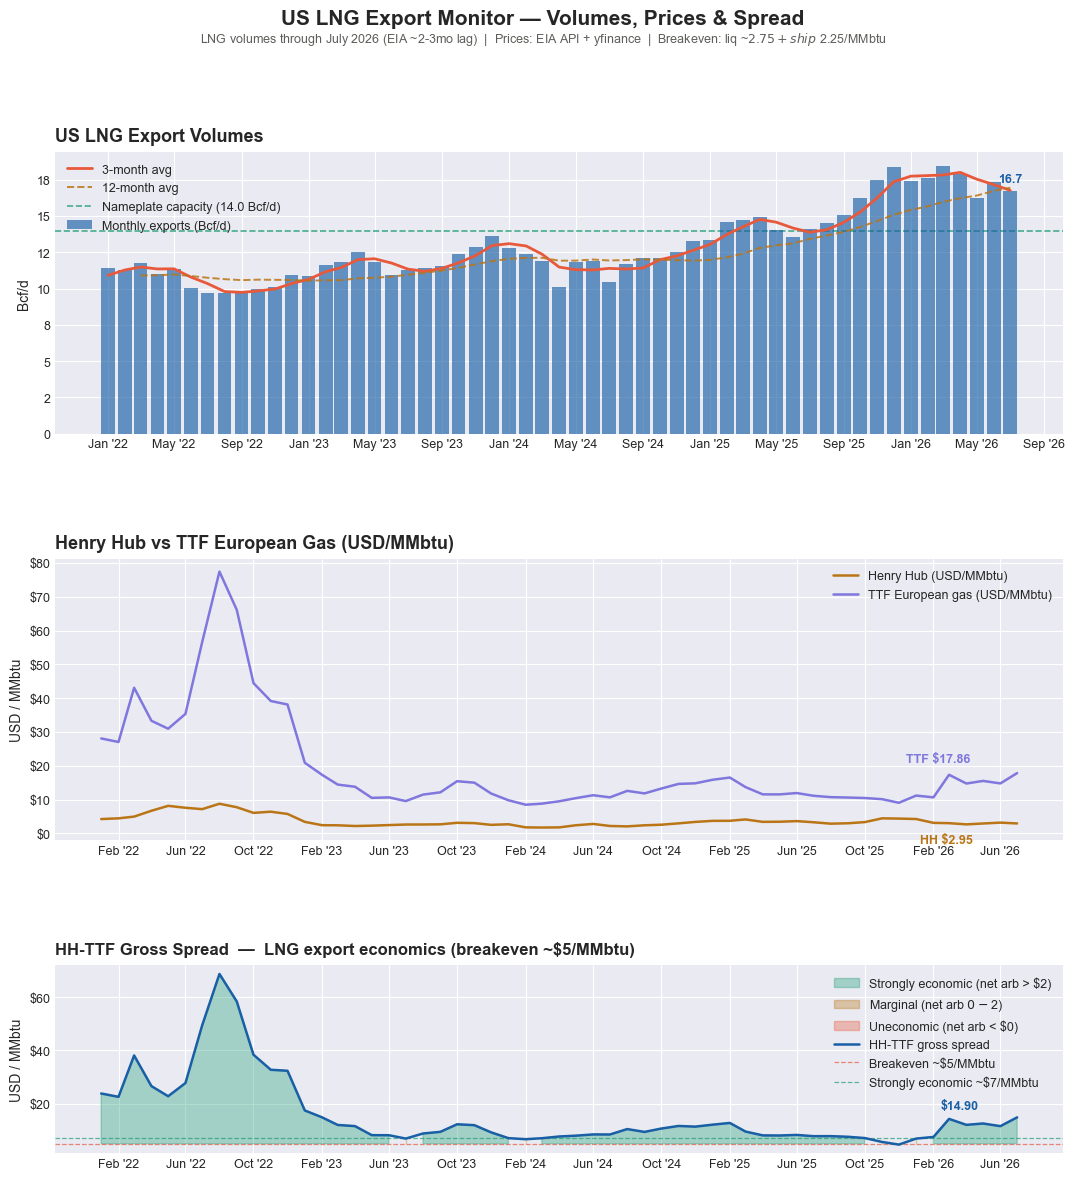


  Chart saved -> c:\Users\mackt\Python Projects\oil_gas_tools\charts\lng_export_monitor_July_2026.png


In [6]:
# ============================================================
# CELL 6 — Three-panel LNG export and spread chart
# ============================================================
# Panel 1 : US LNG export volumes (Bcf/d)
#            Monthly bars + 3-month rolling avg
#            Nameplate capacity reference line
# Panel 2 : Henry Hub vs TTF price (USD/MMbtu)
#            Monthly averages, both on same axis
# Panel 3 : HH-TTF gross spread with breakeven line
#            Color-coded fill:
#              Green  : net arb > $2    (strongly economic)
#              Amber  : net arb $0-$2   (marginal)
#              Red    : net arb < $0    (uneconomic)
# ─────────────────────────────────────────────────────────────

latest_date = df_combined["date"].max().strftime("%B %Y")
latest      = df_combined.iloc[-1]

fig, axes = plt.subplots(
    3, 1,
    figsize      = (13, 13),
    gridspec_kw  = {"hspace": 0.50,
                    "height_ratios": [1.5, 1.5, 1]},
)

ax1, ax2, ax3 = axes

# ── Panel 1: LNG export volumes ───────────────────────────────
ax1.bar(
    df_combined["date"],
    df_combined["lng_bcfd"],
    width     = 25,
    color     = "#185FA5",
    alpha     = 0.65,
    label     = "Monthly exports (Bcf/d)",
    zorder    = 3,
)
ax1.plot(
    df_combined["date"],
    df_combined["bcfd_3m_avg"],
    color     = "#E8593C",
    linewidth = 2.0,
    label     = "3-month avg",
    zorder    = 4,
)
ax1.plot(
    df_combined["date"],
    df_combined["bcfd_12m_avg"],
    color     = "#BA7517",
    linewidth = 1.4,
    linestyle = "--",
    alpha     = 0.85,
    label     = "12-month avg",
    zorder    = 4,
)
ax1.axhline(
    LNG_NAMEPLATE_BCFD,
    color     = "#1D9E75",
    linewidth = 1.2,
    linestyle = "--",
    alpha     = 0.8,
    label     = f"Nameplate capacity ({LNG_NAMEPLATE_BCFD} Bcf/d)",
)

# Annotate latest bar
ax1.annotate(
    f"{latest['lng_bcfd']:.1f}",
    xy         = (df_combined["date"].iloc[-1],
                  latest["lng_bcfd"]),
    xytext     = (0, 6),
    textcoords = "offset points",
    ha         = "center",
    fontsize   = 9,
    color      = "#185FA5",
    fontweight = "bold",
)

ax1.set_title(
    "US LNG Export Volumes",
    fontsize=13, fontweight="bold", loc="left", pad=8,
)
ax1.set_ylabel("Bcf/d", fontsize=10)
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax1.tick_params(axis="both", labelsize=9)
ax1.legend(fontsize=9, loc="upper left",
           framealpha=0.85, edgecolor="none")

# ── Panel 2: HH vs TTF prices ─────────────────────────────────
ax2.plot(
    df_combined["date"],
    df_combined["hh"],
    color     = "#BA7517",
    linewidth = 1.8,
    label     = "Henry Hub (USD/MMbtu)",
    zorder    = 4,
)

if TTF_AVAILABLE:
    ax2.plot(
        df_combined["date"],
        df_combined["ttf_usd_mmbtu"],
        color     = "#7F77DD",
        linewidth = 1.8,
        label     = "TTF European gas (USD/MMbtu)",
        zorder    = 4,
    )

# Annotate latest values
ax2.annotate(
    f"HH ${latest['hh']:.2f}",
    xy         = (df_combined["date"].iloc[-1], latest["hh"]),
    xytext     = (-70, -14),
    textcoords = "offset points",
    fontsize   = 9,
    color      = "#BA7517",
    fontweight = "bold",
)
if TTF_AVAILABLE:
    ax2.annotate(
        f"TTF ${latest['ttf_usd_mmbtu']:.2f}",
        xy         = (df_combined["date"].iloc[-1],
                      latest["ttf_usd_mmbtu"]),
        xytext     = (-80, 8),
        textcoords = "offset points",
        fontsize   = 9,
        color      = "#7F77DD",
        fontweight = "bold",
    )

ax2.set_title(
    "Henry Hub vs TTF European Gas (USD/MMbtu)",
    fontsize=13, fontweight="bold", loc="left", pad=8,
)
ax2.set_ylabel("USD / MMbtu", fontsize=10)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.0f}"))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax2.tick_params(axis="both", labelsize=9)
ax2.legend(fontsize=9, loc="upper right",
           framealpha=0.85, edgecolor="none")

# ── Panel 3: HH-TTF gross spread ──────────────────────────────
if TTF_AVAILABLE:
    dates  = df_combined["date"].values
    spread = df_combined["gross_spread"].values
    arb    = df_combined["net_arb"].values

    # Color-coded fill by export economics zone
    # Green  : net arb > $2  (strongly economic)
    # Amber  : net arb $0-$2 (marginal)
    # Red    : net arb < $0  (uneconomic)
    breakeven_line = LNG_BREAKEVEN        # gross spread = $5 -> net = $0
    strong_line    = LNG_BREAKEVEN + 2    # gross spread = $7 -> net = $2

    ax3.fill_between(dates, breakeven_line, spread,
        where  = (spread >= strong_line),
        alpha  = 0.35, color="#1D9E75",
        label  = f"Strongly economic (net arb > $2)",
        zorder = 2,
    )
    ax3.fill_between(dates, breakeven_line, spread,
        where  = ((spread >= breakeven_line) &
                  (spread < strong_line)),
        alpha  = 0.35, color="#BA7517",
        label  = "Marginal (net arb $0-$2)",
        zorder = 2,
    )
    ax3.fill_between(dates, spread, breakeven_line,
        where  = (spread < breakeven_line),
        alpha  = 0.35, color="#E8593C",
        label  = "Uneconomic (net arb < $0)",
        zorder = 2,
    )

    ax3.plot(dates, spread,
        color="#185FA5", linewidth=1.8,
        label="HH-TTF gross spread", zorder=4)

    # Breakeven and strong economic reference lines
    ax3.axhline(
        breakeven_line,
        color="#E8593C", linewidth=0.9,
        linestyle="--", alpha=0.7,
        label=f"Breakeven ~${breakeven_line:.0f}/MMbtu",
    )
    ax3.axhline(
        strong_line,
        color="#1D9E75", linewidth=0.9,
        linestyle="--", alpha=0.7,
        label=f"Strongly economic ~${strong_line:.0f}/MMbtu",
    )

    # Annotate latest spread
    ax3.annotate(
        f"${latest['gross_spread']:.2f}",
        xy         = (df_combined["date"].iloc[-1],
                      latest["gross_spread"]),
        xytext     = (-55, 6),
        textcoords = "offset points",
        fontsize   = 9,
        color      = "#185FA5",
        fontweight = "bold",
    )

    ax3.set_title(
        "HH-TTF Gross Spread  —  LNG export economics "
        f"(breakeven ~${LNG_BREAKEVEN:.0f}/MMbtu)",
        fontsize=12, fontweight="bold", loc="left", pad=8,
    )
    ax3.set_ylabel("USD / MMbtu", fontsize=10)
    ax3.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f"${x:.0f}"))
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
    ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    ax3.tick_params(axis="both", labelsize=9)
    ax3.legend(fontsize=9, loc="upper right",
               framealpha=0.85, edgecolor="none")
else:
    ax3.text(
        0.5, 0.5,
        "TTF data unavailable — spread analysis not possible\n"
        "For TTF: ICE subscription or Quandl historical data",
        ha="center", va="center",
        transform=ax3.transAxes,
        fontsize=10, color="#5F5E5A",
    )
    ax3.set_title(
        "HH-TTF Gross Spread",
        fontsize=12, fontweight="bold", loc="left", pad=8,
    )

# ── Figure-level annotations ──────────────────────────────────
fig.suptitle(
    "US LNG Export Monitor — Volumes, Prices & Spread",
    fontsize=15, fontweight="bold", y=0.99,
)
fig.text(
    0.5, 0.965,
    f"LNG volumes through {latest_date} (EIA ~2-3mo lag)  |  "
    f"Prices: EIA API + yfinance  |  "
    f"Breakeven: liq ~$2.75 + ship ~$2.25/MMbtu",
    ha="center", fontsize=9, color="#5F5E5A",
)

# ── Save and show ─────────────────────────────────────────────
chart_name = (
    f"lng_export_monitor_"
    f"{latest_date.replace(' ', '_').replace(',', '')}.png"
)
chart_path = CHART_DIR / chart_name
plt.savefig(chart_path, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()
print(f"\n  Chart saved -> {chart_path}")

In [7]:
# ============================================================
# CELL 7 — Signal dashboard and plain English summary
# ============================================================
# Prints structured dashboard:
#   Export volume context (latest, averages, YoY)
#   Capacity utilization
#   Price benchmarks (HH, TTF)
#   Spread economics (gross, net, z-score, signal)
#   Cross-tool context from Tools 3 and 4
#   Plain English morning-note paragraph
# ─────────────────────────────────────────────────────────────

latest      = df_combined.iloc[-1]
latest_date = df_combined["date"].max().strftime("%B %Y")

# Note: latest row is the most recent month with both
# LNG volume AND price data. Due to EIA's ~2-3 month lag
# on LNG volumes, this is typically 2-3 months behind today.
# Price data in Cell 4 is current — the gap is volume-side only.

# ── Price context: pull current prices from df_prices ─────────
# These are more current than the merged df_combined
current_prices = df_prices.iloc[-1]
current_date   = df_prices["date"].max().strftime("%B %Y")
current_hh     = current_prices["hh"]
current_ttf    = (current_prices["ttf_usd_mmbtu"]
                  if TTF_AVAILABLE else float("nan"))
current_spread = (current_ttf - current_hh
                  if TTF_AVAILABLE else float("nan"))
current_net    = (current_spread - LNG_BREAKEVEN
                  if TTF_AVAILABLE else float("nan"))
current_signal = export_signal(current_net)

# ── Load Tool 3 and Tool 4 data for cross-tool context ────────
# Tool 3: gas storage
t3_note = "Tool 3 CSV not found — run gas_storage_tracker first"
t3_hh_sigma = float("nan")

storage_files = sorted(
    glob.glob(str(DATA_DIR / "gas_storage*.csv")),
    key=lambda f: os.path.getmtime(f)
)

if storage_files:
    df_t3      = pd.read_csv(storage_files[-1], parse_dates=["date"])
    t3_latest  = df_t3.iloc[-1]
    t3_date    = t3_latest["date"].strftime("%B %d, %Y")
    t3_us      = t3_latest["us_total"]
    t3_us_dev  = t3_latest["dev_bcf"]
    t3_us_sig  = t3_latest["dev_std"]
    t3_sc_dev  = t3_latest["sc_dev_bcf"]
    t3_sc_sig  = t3_latest["sc_dev_std"]
    t3_hh_sigma = t3_us_sig
    t3_us_rel  = "above" if t3_us_dev >= 0 else "below"
    t3_sc_rel  = "below" if t3_sc_dev < 0  else "above"
    t3_note = (
        f"Storage ({t3_date}): L48 {t3_us:.0f} Bcf "
        f"({t3_us_dev:+.0f} Bcf {t3_us_rel} 5yr avg, "
        f"{t3_us_sig:+.2f} sigma) | "
        f"S.Central {t3_sc_dev:+.0f} Bcf {t3_sc_rel} avg "
        f"({t3_sc_sig:+.2f} sigma)"
    )

# Tool 4: futures curve
t4_note = "Tool 4 CSV not found — run futures_curve_monitor first"
curve_files = sorted(
    glob.glob(str(DATA_DIR / "futures_curve*.csv")),
    key=lambda f: os.path.getmtime(f)
)
if curve_files:
    df_t4     = pd.read_csv(curve_files[-1], parse_dates=["date"])
    t4_latest = df_t4.iloc[-1]
    t4_wti    = t4_latest.get("wti", float("nan"))
    t4_ng_spr = t4_latest.get("ng_roll_spread", float("nan"))
    t4_ng_str = ("contango" if t4_ng_spr < 0
                 else "backwardation" if t4_ng_spr > 0
                 else "flat")
    t4_note = (
        f"Futures ({df_t4['date'].max().strftime('%b %d, %Y')}): "
        f"WTI ${t4_wti:.2f}/bbl | "
        f"NG curve: {t4_ng_str} "
        f"(M1-M2 {t4_ng_spr:+.3f}/MMbtu)"
    )

# ── Spread trend ──────────────────────────────────────────────
# Is the spread widening or narrowing over the last 3 months?
if TTF_AVAILABLE and len(df_combined) >= 4:
    spread_3m_ago = df_combined["gross_spread"].iloc[-4]
    spread_now    = df_combined["gross_spread"].iloc[-1]
    spread_chg    = spread_now - spread_3m_ago
    spread_trend  = ("widening" if spread_chg > 0.5
                     else "narrowing" if spread_chg < -0.5
                     else "stable")
else:
    spread_chg   = float("nan")
    spread_trend = "N/A"

# ── Print dashboard ───────────────────────────────────────────
print("=" * 62)
print("LNG EXPORT & SPREAD DASHBOARD")
print(f"Volume data through {latest_date}  "
      f"|  Price data through {current_date}")
print("=" * 62)

print(f"""
  US LNG EXPORT VOLUMES
  {'─' * 54}
  Latest month     : {latest['lng_bcfd']:.1f} Bcf/d  ({latest_date})
  3-month avg      : {latest['bcfd_3m_avg']:.1f} Bcf/d
  12-month avg     : {latest['bcfd_12m_avg']:.1f} Bcf/d
  YoY change       : {latest['lng_bcfd_yoy']:+.1f} Bcf/d  ({latest['lng_bcfd_yoy_pct']:+.0f}%)
  Nameplate cap    : {LNG_NAMEPLATE_BCFD:.1f} Bcf/d  (approx)
  Utilization      : {latest['utilization_pct']:.0f}%  (>100% includes re-exports)

  CURRENT PRICE BENCHMARKS  (more recent than volume data)
  {'─' * 54}
  Henry Hub        : ${current_hh:.3f}/MMbtu  ({current_date} avg)
  TTF European gas : {'${:.2f}/MMbtu'.format(current_ttf) if TTF_AVAILABLE else 'N/A'}
  HH-TTF gross spd : {'${:.2f}/MMbtu'.format(current_spread) if TTF_AVAILABLE else 'N/A'}
  Net arbitrage    : {'${:.2f}/MMbtu  (after ~${:.2f} breakeven)'.format(current_net, LNG_BREAKEVEN) if TTF_AVAILABLE else 'N/A'}
  Export signal    : {current_signal}

  SPREAD ANALYTICS  (based on latest combined data)
  {'─' * 54}
  Gross spread     : ${latest['gross_spread']:.2f}/MMbtu  ({latest_date})
  Net arb          : ${latest['net_arb']:.2f}/MMbtu
  Spread z-score   : {latest['spread_z']:+.2f} sigma  (vs 12-month rolling avg)
  3-month trend    : {spread_trend}  ({spread_chg:+.2f}/MMbtu vs 3mo ago)
  Signal           : {latest['export_signal']}
""")

# ── Plain English summary ─────────────────────────────────────
# Build interpretation dynamically
if TTF_AVAILABLE:
    if current_net > 5:
        economics_note = (
            f"strongly economic at ${current_net:.2f}/MMbtu net — "
            f"all available capacity should run flat out"
        )
    elif current_net > 2:
        economics_note = (
            f"economic at ${current_net:.2f}/MMbtu net — "
            f"exports incentivized at current prices"
        )
    elif current_net > 0:
        economics_note = (
            f"marginally economic at ${current_net:.2f}/MMbtu net — "
            f"spot cargo cancellations possible"
        )
    else:
        economics_note = (
            f"uneconomic at ${current_net:.2f}/MMbtu net — "
            f"cargo cancellations likely on spot volumes"
        )

    storage_hh_note = (
        "Ample US gas storage supports continued low Henry Hub "
        "prices and wide export spreads."
        if not pd.isna(t3_hh_sigma) and t3_hh_sigma > 0
        else
        "Below-average US gas storage could pressure Henry Hub "
        "higher, which would compress export spreads."
        if not pd.isna(t3_hh_sigma) and t3_hh_sigma < -0.5
        else
        "US gas storage near seasonal average — neutral for "
        "Henry Hub price and export spread outlook."
    )
else:
    economics_note  = "TTF unavailable — economics assessment N/A"
    storage_hh_note = ""

print("=" * 62)
print("  PLAIN ENGLISH SUMMARY")
print("=" * 62)
print(f"""
  As of {latest_date} (latest volume data), the US exported
  {latest['lng_bcfd']:.1f} Bcf/d of LNG — {latest['lng_bcfd_yoy']:+.1f} Bcf/d
  year-on-year (+{latest['lng_bcfd_yoy_pct']:.0f}%), running at
  {latest['utilization_pct']:.0f}% of approximate nameplate capacity.

  Current LNG export economics ({current_date}) are
  {economics_note}.

  Henry Hub at ${current_hh:.3f}/MMbtu vs TTF at
  ${current_ttf:.2f}/MMbtu produces a gross spread of
  ${current_spread:.2f}/MMbtu. Against a ~${LNG_BREAKEVEN:.2f}/MMbtu
  all-in breakeven, the net arbitrage is
  ${current_net:.2f}/MMbtu to Europe.

  {storage_hh_note}
""")

print("=" * 62)
print("  CROSS-TOOL CONTEXT")
print("=" * 62)
print(f"""
  Tool 3 — Gas storage:
  {t3_note}

  Tool 4 — Futures curve:
  {t4_note}
""")
print("=" * 62)

LNG EXPORT & SPREAD DASHBOARD
Volume data through July 2026  |  Price data through October 2026

  US LNG EXPORT VOLUMES
  ──────────────────────────────────────────────────────
  Latest month     : 16.7 Bcf/d  (July 2026)
  3-month avg      : 16.8 Bcf/d
  12-month avg     : 17.0 Bcf/d
  YoY change       : +2.6 Bcf/d  (+19%)
  Nameplate cap    : 14.0 Bcf/d  (approx)
  Utilization      : 120%  (>100% includes re-exports)

  CURRENT PRICE BENCHMARKS  (more recent than volume data)
  ──────────────────────────────────────────────────────
  Henry Hub        : $3.110/MMbtu  (October 2026 avg)
  TTF European gas : $25.16/MMbtu
  HH-TTF gross spd : $22.05/MMbtu
  Net arbitrage    : $17.05/MMbtu  (after ~$5.00 breakeven)
  Export signal    : STRONGLY ECONOMIC

  SPREAD ANALYTICS  (based on latest combined data)
  ──────────────────────────────────────────────────────
  Gross spread     : $14.90/MMbtu  (July 2026)
  Net arb          : $9.90/MMbtu
  Spread z-score   : +1.58 sigma  (vs 12-month r

In [8]:
# ============================================================
# CELL 8 — Save data and wrap up
# ============================================================
# Saves combined dataset to CSV.
# Documents verified EIA series codes and workflow.
# ─────────────────────────────────────────────────────────────

# ── Save combined dataset ─────────────────────────────────────
save_cols = [
    "date",
    "lng_bcf_month", "lng_bcfd",
    "bcfd_3m_avg", "bcfd_12m_avg",
    "lng_bcfd_yoy", "lng_bcfd_yoy_pct",
    "nameplate_bcfd", "utilization_pct",
    "hh", "ttf_usd_mmbtu",
    "gross_spread", "net_arb",
    "spread_mean_12m", "spread_std_12m", "spread_z",
    "export_signal", "cancel_flag",
]
save_cols = [c for c in save_cols if c in df_combined.columns]

csv_filename = (
    f"lng_export_monitor_"
    f"{latest_date.replace(' ', '_')}.csv"
)
csv_path = DATA_DIR / csv_filename
df_combined[save_cols].to_csv(csv_path, index=False)
print(f"  Data saved -> {csv_path}")

# ── Also save current prices separately ──────────────────────
# Useful for cross-tool reference — more current than combined
prices_path = DATA_DIR / "lng_current_prices.csv"
df_prices.to_csv(prices_path, index=False)
print(f"  Current prices saved -> {prices_path}")

# ── Save commentary log ───────────────────────────────────────
commentary_path = DATA_DIR / "lng_export_commentary_log.txt"

# Build TTF-dependent strings safely
ttf_str    = (f"${current_ttf:.2f}/MMbtu"
              if TTF_AVAILABLE else "N/A")
spread_str = (f"${current_spread:.2f}/MMbtu"
              if TTF_AVAILABLE else "N/A")
net_str    = (f"${current_net:.2f}/MMbtu"
              if TTF_AVAILABLE else "N/A")

commentary_entry = f"""
{'=' * 62}
LNG EXPORT & SPREAD COMMENTARY
Run date     : {dt.date.today().strftime('%B %d, %Y')}
Volume data  : {latest_date}  (EIA ~2-3mo lag)
Price data   : {current_date}
{'=' * 62}

METRICS SNAPSHOT — VOLUMES ({latest_date})
  Latest exports   : {latest['lng_bcfd']:.1f} Bcf/d
  3-month avg      : {latest['bcfd_3m_avg']:.1f} Bcf/d
  12-month avg     : {latest['bcfd_12m_avg']:.1f} Bcf/d
  YoY change       : {latest['lng_bcfd_yoy']:+.1f} Bcf/d ({latest['lng_bcfd_yoy_pct']:+.0f}%)
  Utilization      : {latest['utilization_pct']:.0f}% of {LNG_NAMEPLATE_BCFD:.1f} Bcf/d nameplate

METRICS SNAPSHOT — PRICES ({current_date})
  Henry Hub        : ${current_hh:.3f}/MMbtu
  TTF European gas : {ttf_str}
  HH-TTF gross spd : {spread_str}
  Net arbitrage    : {net_str}
  Export signal    : {current_signal}
  Spread z-score   : {latest['spread_z']:+.2f} sigma  (vs 12m rolling avg)
  Spread trend     : {spread_trend} ({spread_chg:+.2f}/MMbtu vs 3mo ago)

CROSS-TOOL CONTEXT
  Tool 3: {t3_note}
  Tool 4: {t4_note}

PLAIN ENGLISH SUMMARY
  As of {latest_date} (latest volume data), the US exported
  {latest['lng_bcfd']:.1f} Bcf/d of LNG — {latest['lng_bcfd_yoy']:+.1f} Bcf/d
  year-on-year ({latest['lng_bcfd_yoy_pct']:+.0f}%), running at
  {latest['utilization_pct']:.0f}% of approximate nameplate capacity.
  Current LNG export economics ({current_date}) are {economics_note}.
  Henry Hub at ${current_hh:.3f}/MMbtu vs TTF at {ttf_str}
  produces a gross spread of {spread_str}.
  Against a ~${LNG_BREAKEVEN:.2f}/MMbtu all-in breakeven,
  the net arbitrage is {net_str} to Europe.
  {storage_hh_note}

"""

with open(commentary_path, "a", encoding="utf-8") as f:
    f.write(commentary_entry)

print(f"  Commentary logged -> {commentary_path.name}")

# ── Next release reminder ─────────────────────────────────────
today = dt.date.today()

# EIA LNG export data: released monthly, ~8-10 weeks lag
# Typically available around the 31st of the following month
# e.g. January data available ~late March
next_data_month = (
    df_combined["date"].max() + pd.DateOffset(months=2)
).strftime("%B %Y")

print()
print("=" * 62)
print("  TOOL 5 COMPLETE — LNG Export & Spread Monitor")
print("=" * 62)
print(f"""
  What this notebook built:
  {'─' * 54}
  Pulled EIA monthly US LNG export volumes (ENG series)
  Computed Bcf/d, utilization vs nameplate capacity
  Built 3-month and 12-month rolling volume averages
  Fetched Henry Hub and TTF prices via yfinance
  Converted TTF from EUR/MWh to USD/MMbtu correctly
  Computed HH-TTF gross spread and net arbitrage
  Built 12-month rolling spread statistics and z-score
  3-panel chart: volumes, prices, spread economics
  Dynamic cross-tool context from Tools 3 and 4
  Signal dashboard with current and lagged data clearly split

  Estimated next volume data update:
  {'─' * 54}
  Next available LNG volume month : ~{next_data_month}
  EIA publication lag             : ~2-3 months
  Price data                      : current (refresh anytime)

  EIA series reference (verified April 2026):
  {'─' * 54}
  Old route (deprecated) : /natural-gas/move/lnge/
  New route              : /natural-gas/move/expc/data/
  Process code           : ENG (Liquefied US NG Exports)
  Duoarea               : NUS-Z00 (US Total)
  Frequency             : monthly (weekly no longer available)
  Units                 : MMcf/month -> convert to Bcf/d
  Note: ENG includes re-exports, so utilization can exceed
        nameplate capacity. This is expected, not an error.

  TTF conversion (corrected April 2026):
  {'─' * 54}
  Raw TTF from yfinance : EUR/MWh
  Conversion formula    : USD/MMbtu = EUR/MWh * EUR_USD * 0.29307
  Key: MULTIPLY by 0.29307, not divide (common error)
  Sanity check          : ~46 EUR/MWh -> ~$16/MMbtu at 1.18 FX

  Cross-tool workflow:
  {'─' * 54}
  Thursday 10:30am ET  -> Run Tool 3 (EIA gas storage)
  Thursday afternoon   -> Run Tool 5 (spread updates via TTF)
  Monthly (when new    -> Rerun Tool 5 for updated volumes
  EIA data available)
  Anytime              -> Run Tool 5 for current price/spread

  LNG breakeven reference:
  {'─' * 54}
  Liquefaction fee : ~$2.25-3.50/MMbtu  (Cheniere SPA tolling)
  Shipping to EU   : ~$1.50-2.50/MMbtu  (US Gulf to Europe)
  Shipping to Asia : ~$2.00-3.00/MMbtu  (via Panama Canal)
  This tool uses   : $5.00/MMbtu as round midpoint
  Update LNG_BREAKEVEN in Cell 1 if market rates shift
""")
print("=" * 62)

  Data saved -> c:\Users\mackt\Python Projects\oil_gas_tools\data\lng_export_monitor_July_2026.csv
  Current prices saved -> c:\Users\mackt\Python Projects\oil_gas_tools\data\lng_current_prices.csv
  Commentary logged -> lng_export_commentary_log.txt

  TOOL 5 COMPLETE — LNG Export & Spread Monitor

  What this notebook built:
  ──────────────────────────────────────────────────────
  Pulled EIA monthly US LNG export volumes (ENG series)
  Computed Bcf/d, utilization vs nameplate capacity
  Built 3-month and 12-month rolling volume averages
  Fetched Henry Hub and TTF prices via yfinance
  Converted TTF from EUR/MWh to USD/MMbtu correctly
  Computed HH-TTF gross spread and net arbitrage
  Built 12-month rolling spread statistics and z-score
  3-panel chart: volumes, prices, spread economics
  Dynamic cross-tool context from Tools 3 and 4
  Signal dashboard with current and lagged data clearly split

  Estimated next volume data update:
  ────────────────────────────────────────────────